In [1]:
import sqlite3
import urllib.request
import os
import pandas as pd

# Download the Chinook database once and save it in this folder
url = "https://github.com/lerocha/chinook-database/releases/download/v1.4.5/Chinook_Sqlite.sqlite"
if not os.path.exists("chinook.db"):
    urllib.request.urlretrieve(url, "chinook.db")

# Connect to it
conn = sqlite3.connect("chinook.db")

# A small helper: give it a SQL query, get back a table
def run(query):
    return pd.read_sql_query(query, conn)

# List the tables and how many rows each has
tables = run("SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name")
rows = [run(f'SELECT COUNT(*) AS n FROM "{t}"')["n"][0] for t in tables["name"]]
tables["rows"] = rows
tables

,name,rows
0,Album,347
1,Artist,275
2,Customer,59
3,Employee,8
4,Genre,25
5,Invoice,412
6,InvoiceLine,2240
7,MediaType,5
8,Playlist,18
9,PlaylistTrack,8715


In [2]:
# 1. Peek at the Invoice table (one row per purchase)
display(run("""
    SELECT *
    FROM Invoice
    LIMIT 5
"""))

# 2. Question: how much revenue did the store make each year?
display(run("""
    SELECT strftime('%Y', InvoiceDate) AS year,
           COUNT(*)                    AS invoices,
           ROUND(SUM(Total), 2)        AS revenue
    FROM Invoice
    GROUP BY year
    ORDER BY year
"""))

,InvoiceId,CustomerId,InvoiceDate,BillingAddress,BillingCity,BillingState,BillingCountry,BillingPostalCode,Total
0,1,2,2009-01-01 00:00:00,Theodor-Heuss-Straße 34,Stuttgart,NaN,Germany,70174,1.98
1,2,4,2009-01-02 00:00:00,Ullevålsveien 14,Oslo,NaN,Norway,0171,3.96
2,3,8,2009-01-03 00:00:00,Grétrystraat 63,Brussels,NaN,Belgium,1000,5.94
3,4,14,2009-01-06 00:00:00,8210 111 ST NW,Edmonton,AB,Canada,T6G 2C7,8.91
4,5,23,2009-01-11 00:00:00,69 Salem Street,Boston,MA,USA,2113,13.86


,year,invoices,revenue
0,2009,83,449.46
1,2010,83,481.45
2,2011,83,469.58
3,2012,83,477.53
4,2013,80,450.58


,country,invoices,revenue
0,USA,91,523.06
1,Canada,56,303.96
2,France,35,195.10
3,Brazil,35,190.10
4,Germany,28,156.48
5,United Kingdom,21,112.86
6,Czech Republic,14,90.24
7,Portugal,14,77.24
8,India,13,75.26
9,Chile,7,46.62


,customer,Country,purchases,total_spent
0,Helena Holý,Czech Republic,7,49.62
1,Richard Cunningham,USA,7,47.62
2,Luis Rojas,Chile,7,46.62
3,Ladislav Kovács,Hungary,7,45.62
4,Hugh O'Reilly,Ireland,7,45.62


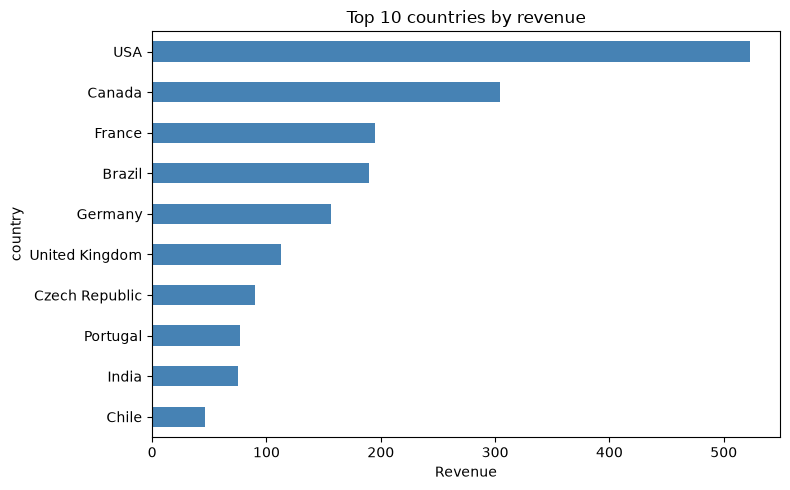

In [3]:
import matplotlib.pyplot as plt
os.makedirs("images", exist_ok=True)

# 1. Which countries bring in the most revenue?
country = run("""
    SELECT BillingCountry        AS country,
           COUNT(*)              AS invoices,
           ROUND(SUM(Total), 2)  AS revenue
    FROM Invoice
    GROUP BY BillingCountry
    ORDER BY revenue DESC
    LIMIT 10
""")
display(country)

# 2. Who are the top 5 customers? (JOIN links the Customer and Invoice tables)
display(run("""
    SELECT c.FirstName || ' ' || c.LastName AS customer,
           c.Country,
           COUNT(i.InvoiceId)               AS purchases,
           ROUND(SUM(i.Total), 2)           AS total_spent
    FROM Customer c
    JOIN Invoice i ON i.CustomerId = c.CustomerId
    GROUP BY c.CustomerId
    ORDER BY total_spent DESC
    LIMIT 5
"""))

# 3. Chart of the top 10 countries
country.sort_values("revenue").plot(
    kind="barh", x="country", y="revenue", legend=False, figsize=(8, 5), color="steelblue"
)
plt.title("Top 10 countries by revenue")
plt.xlabel("Revenue")
plt.tight_layout()
plt.savefig("images/revenue-by-country.png", dpi=150, bbox_inches="tight")
plt.show()

,country,customers,revenue,revenue_per_customer
0,USA,13,523.06,40.24
1,Canada,8,303.96,37.99
2,France,5,195.10,39.02
3,Brazil,5,190.10,38.02
4,Germany,4,156.48,39.12
5,United Kingdom,3,112.86,37.62
6,Czech Republic,2,90.24,45.12
7,Portugal,2,77.24,38.62
8,India,2,75.26,37.63
9,Chile,1,46.62,46.62


,genre,tracks_sold,revenue
0,Rock,835,826.65
1,Latin,386,382.14
2,Metal,264,261.36
3,Alternative & Punk,244,241.56
4,TV Shows,47,93.53
5,Jazz,80,79.20
6,Blues,61,60.39
7,Drama,29,57.71
8,Classical,41,40.59
9,R&B/Soul,41,40.59


,artist,revenue
0,Iron Maiden,138.60
1,U2,105.93
2,Metallica,90.09
3,Led Zeppelin,86.13
4,Lost,81.59


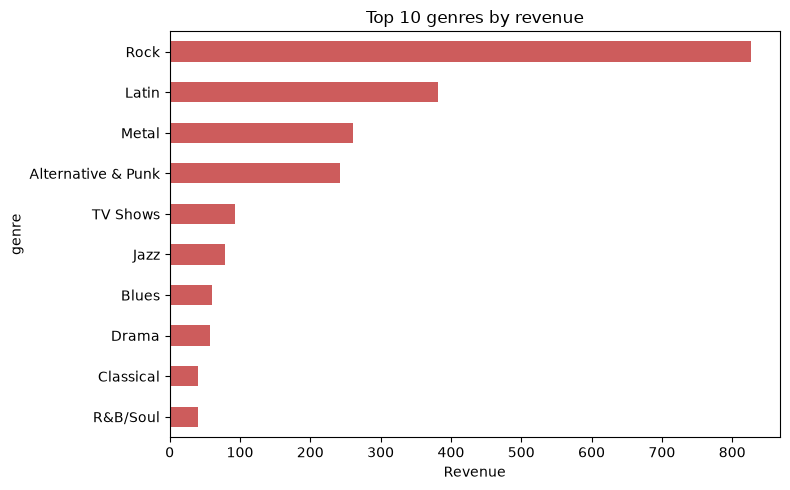

In [4]:
# 1. Is the USA on top because it has more customers, or because each one spends more?
display(run("""
    SELECT c.Country                                        AS country,
           COUNT(DISTINCT c.CustomerId)                     AS customers,
           ROUND(SUM(i.Total), 2)                           AS revenue,
           ROUND(SUM(i.Total) / COUNT(DISTINCT c.CustomerId), 2) AS revenue_per_customer
    FROM Customer c
    JOIN Invoice i ON i.CustomerId = c.CustomerId
    GROUP BY c.Country
    ORDER BY revenue DESC
    LIMIT 10
"""))

# 2. Best-selling genres
genre = run("""
    SELECT g.Name                                   AS genre,
           SUM(il.Quantity)                         AS tracks_sold,
           ROUND(SUM(il.UnitPrice * il.Quantity), 2) AS revenue
    FROM InvoiceLine il
    JOIN Track t ON t.TrackId = il.TrackId
    JOIN Genre g ON g.GenreId = t.GenreId
    GROUP BY g.GenreId
    ORDER BY revenue DESC
    LIMIT 10
""")
display(genre)

# 3. Top 5 artists by revenue
display(run("""
    SELECT ar.Name                                   AS artist,
           ROUND(SUM(il.UnitPrice * il.Quantity), 2) AS revenue
    FROM InvoiceLine il
    JOIN Track t  ON t.TrackId  = il.TrackId
    JOIN Album al ON al.AlbumId = t.AlbumId
    JOIN Artist ar ON ar.ArtistId = al.ArtistId
    GROUP BY ar.ArtistId
    ORDER BY revenue DESC
    LIMIT 5
"""))

# 4. Chart of the top genres
genre.sort_values("revenue").plot(
    kind="barh", x="genre", y="revenue", legend=False, figsize=(8, 5), color="indianred"
)
plt.title("Top 10 genres by revenue")
plt.xlabel("Revenue")
plt.tight_layout()
plt.savefig("images/revenue-by-genre.png", dpi=150, bbox_inches="tight")
plt.show()

Months: 60
Highest month: {'month': '2010-01', 'revenue': 52.62}
Lowest month: {'month': '2011-11', 'revenue': 23.76}


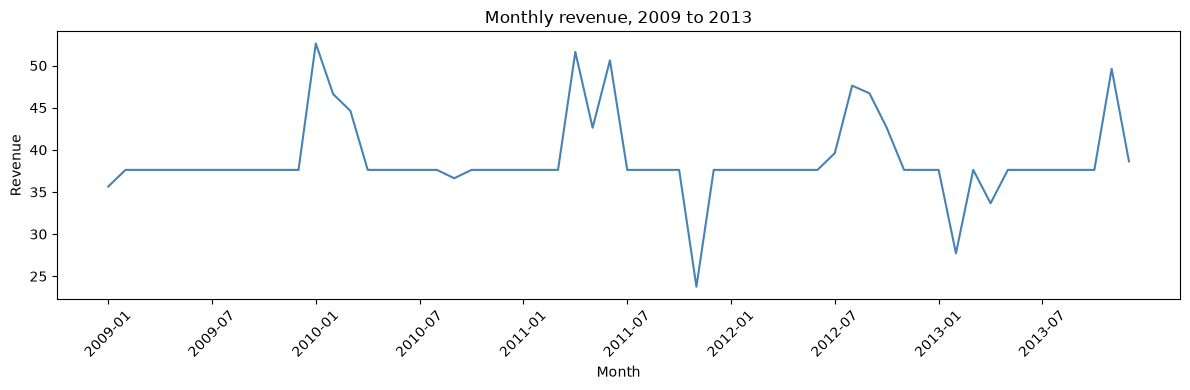

In [5]:
# Revenue for each month
monthly = run("""
    SELECT strftime('%Y-%m', InvoiceDate) AS month,
           ROUND(SUM(Total), 2)           AS revenue
    FROM Invoice
    GROUP BY month
    ORDER BY month
""")

print("Months:", len(monthly))
print("Highest month:", monthly.loc[monthly["revenue"].idxmax()].to_dict())
print("Lowest month:", monthly.loc[monthly["revenue"].idxmin()].to_dict())

monthly.plot(x="month", y="revenue", legend=False, figsize=(12, 4), color="steelblue")
plt.title("Monthly revenue, 2009 to 2013")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(range(0, len(monthly), 6), monthly["month"][::6], rotation=45)
plt.tight_layout()
plt.savefig("images/monthly-revenue.png", dpi=150, bbox_inches="tight")
plt.show()